# Cohort-Wide Cross-Model Benchmark Comparison

This notebook performs a centralized cohort-level comparison across all 8 model configurations: 
1. Logistic Regression (FCz-theta)
2. Logistic Regression (Oz-alpha)
3. Riemannian TS-LDA
4. EEGNet Agnostic
5. EEGNet Clustering
6. ST-GNN
7. ST-EEGFormer
8. LaBraM

We load the cached cross-validation metrics for each model, plot comparative boxplots, connect subject trajectories, run pairwise Wilcoxon signed-rank tests with false discovery rate (FDR) correction, and generate a summary ranking table.

In [64]:
import sys
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import wilcoxon
from mne.stats import fdr_correction

try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()
SRC_DIR = (
    Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
    if "google.colab" in sys.modules
    else NOTEBOOK_DIR.parent.parent / "src"
)

try:
    from google.colab import drive

    IN_COLAB = True
    drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from br_analysis import detect_project_paths, get_task_config

warnings.filterwarnings("ignore")
RANDOM_SEED = 42

In [65]:
# Unified Environment Setup (Local, Colab, Kaggle)
import os
import sys
from pathlib import Path

IS_KAGGLE = os.path.exists('/kaggle/working')
IS_COLAB = 'google.colab' in sys.modules

if IS_KAGGLE:
    print('Detected Kaggle environment. Installing dependencies...')
    !pip install -q mne braindecode[hub] safetensors timm shap huggingface_hub
elif IS_COLAB:
    print('Detected Google Colab environment. Installing dependencies...')
    !pip install -q mne braindecode[hub] safetensors timm shap huggingface_hub
    from google.colab import drive
    drive.mount('/content/drive')

# Locate workspace source directory
try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()

if IS_KAGGLE:
    # Dynamically find the unzipped dataset path
    dataset_root = None
    for root, dirs, files in os.walk('/kaggle/input'):
        if 'tfg-nils-2026-dataset.zip' in files or 'br_analysis' in dirs:
            dataset_root = Path(root)
            break
    SRC_DIR = dataset_root if dataset_root else Path('/kaggle/input/tfg-nils-2026-dataset')
elif IS_COLAB:
    SRC_DIR = Path('/content/drive/MyDrive/TFG_Nils_2026/03_Codi')
else:
    SRC_DIR = NOTEBOOK_DIR.parent

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print(f'Using source directory: {SRC_DIR}')

Using source directory: c:\Users\nils\Documents\Universitat\TFG\src


In [66]:
# TASK CONFIGURATION: Change to "im_vs_ip" to run comparison for Task 2
TASK_TAG = "c_vs_ip"
TASK_TAG_DISPLAY = TASK_TAG.split("_vs_")[0].upper() + " vs " + TASK_TAG.split("_vs_")[1].upper()

paths = detect_project_paths("cross_model_comparison", in_colab=IN_COLAB)
task = get_task_config(TASK_TAG, paths.analysis_root)

print(f"Project directory: {paths.project_dir}")
print(f"Analysis root: {paths.analysis_root}")
print(f"Selected task: {task.name} ({task.class_0} vs {task.class_1})")

Project directory: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Analysis root: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi
Selected task: c_vs_i (Congruent vs Incongruent_Pure)


In [67]:
import mne
import torch
from br_analysis import (
    detect_project_paths,
    get_task_config,
    load_raw_epoch_dataset,
    RawEpochSpec,
    get_epochs_grid,
    BinaryTaskConfig,
    COMMON_BAND_RANGES,
    TARGET_BANDS_CLUSTERS,
    temporal_band_features,
    electrode_distance_adjacency,
    load_fused_band_dataset,
    FusedBandSpec,
    temporal_stratified_splits,
)
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    standardize_train_test,
    build_dataloader,
    _evaluate,
)
from br_analysis.torch_models import (
    STGNNChebConv,
    EEGNet,
)
from br_analysis.pretrained import (
    prepare_lora_backbone,
    load_backbone_weights,
    BackboneClassifier,
    align_channels_to_steegformer,
)
from br_analysis import mae_vit_small_patch16
from braindecode.models import InterpolatedLaBraM

# ── TASK CONFIGURATION ────────────────────────────────────────────────────────
# Change TASK_TAG to "im_vs_ip" to run the Task 2 comparison instead
TASK_TAG = "c_vs_ip"
paths = detect_project_paths("cross_model_comparison")
task = get_task_config(TASK_TAG, paths.analysis_root)

# ── subject list ──────────────────────────────────────────────────────────────
subject_ids = pd.read_csv(task.selected_subjects_csv)["subject"].tolist()

mne.set_log_level("WARNING")
RANDOM_SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Working Paths:")
print("  Cache:", paths.cache_dir)
print("  Tables:", paths.tables_dir)
print("  Figures:", paths.figures_dir)
print(f"Task: {TASK_TAG_DISPLAY}  |  Subjects: {len(subject_ids)}")

# ── Define model directory paths ──────────────────────────────────────────────
task_name_lc = "c_vs_ip" if "c_vs_ip" in TASK_TAG else "im_vs_ip"
if task_name_lc == "c_vs_ip":
    lr_dir = "c_vs_i"
    riemann_dir = "c_vs_i_riemann"
    eegnet_dir = "c_vs_i_eegnet"
    stgnn_dir = "c_vs_i_stgnn"
    steegformer_dir = "c_vs_i_steegformer"
    labram_dir = "c_vs_i_labram"
else:
    lr_dir = "im_vs_ip"
    riemann_dir = "im_vs_ip_riemann"
    eegnet_dir = "im_vs_ip_eegnet"
    stgnn_dir = "im_vs_ip_stgnn"
    steegformer_dir = "im_vs_ip_steegformer"
    labram_dir = "im_vs_ip_labram"

print(
    f"Model Directories: LR={lr_dir}, Riemann={riemann_dir}, EEGNet={eegnet_dir}, ST-GNN={stgnn_dir}, ST-EEGFormer={steegformer_dir}, LaBraM={labram_dir}"
)

Working Paths:
  Cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\cache
  Tables: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\tables
  Figures: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\figures
Task: C vs IP  |  Subjects: 30
Model Directories: LR=c_vs_i, Riemann=c_vs_i_riemann, EEGNet=c_vs_i_eegnet, ST-GNN=c_vs_i_stgnn, ST-EEGFormer=c_vs_i_steegformer, LaBraM=c_vs_i_labram


## Cohort Accuracies Comparison (Boxplot & Stripplot)

We visualize the distribution of classification accuracies across subjects for each of the 8 model variants.

In [ ]:
# ── Build df_merged: per-subject × per-model accuracy table ─────────────────
# Loads the per-fold CV cache files produced by each model notebook and
# computes the mean accuracy per subject, for every available model.
# Models whose cache files do not exist are simply skipped.

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import accuracy_score

if "subject_ids" not in dir():
    subject_ids = pd.read_csv(task.selected_subjects_csv)["subject"].tolist()

# ── file names (mirrors comp_roc_pr_code) ────────────────────────────────────
if "c_vs_ip" in TASK_TAG:
    lr_file = "oof_predictions_c_vs_i_FCz_theta_Oz_alpha.npz"
    riemann_file = "oof_predictions_c_vs_i_riemann_fused.npz"
    eegnet_agn_file = "oof_predictions_c_vs_ip_eegnet_agnostic.npz"
    eegnet_clust_file = "oof_predictions_c_vs_ip_eegnet_clustering.npz"
    stgnn_file = "oof_predictions_c_vs_ip_stgnn.npz"
    steeg_file = "oof_predictions_c_vs_ip_steegformer.npz"
    labram_file = "oof_predictions_c_vs_ip_labram.npz"
elif "im_vs_ip" in TASK_TAG:
    lr_file = "oof_predictions_im_vs_ip_FCz_theta_Oz_alpha.npz"
    riemann_file = "oof_predictions_im_vs_ip_riemann_fused.npz"
    eegnet_agn_file = "oof_predictions_im_vs_ip_eegnet_agnostic.npz"
    eegnet_clust_file = "oof_predictions_im_vs_ip_eegnet_clustering.npz"
    stgnn_file = "oof_predictions_im_vs_ip_stgnn.npz"
    steeg_file = "oof_predictions_im_vs_ip_steegformer.npz"
    labram_file = "oof_predictions_im_vs_ip_labram.npz"

cache_paths_acc = {
    "LR_theta": paths.analysis_root / lr_dir / "cache" / lr_file,
    "LR_alpha": paths.analysis_root / lr_dir / "cache" / lr_file,
    "Riemann": paths.analysis_root / riemann_dir / "cache" / riemann_file,
    "EEGNet_Agnostic": paths.cache_dir / eegnet_agn_file,
    "EEGNet_Clustering": paths.cache_dir / eegnet_clust_file,
    "ST_GNN": paths.cache_dir / stgnn_file,
    "ST_EEGFormer": paths.cache_dir / steeg_file,
    "LaBraM": paths.cache_dir / labram_file,
}


# ── prob / y_true key helpers ─────────────────────────────────────────────────
def _prob_key(model_name, sub):
    if model_name == "LR_theta":
        return f"{sub}_FCz-theta_prob"
    if model_name == "LR_alpha":
        return f"{sub}_Oz-alpha_prob"
    if model_name == "Riemann":
        return f"{sub}_fused_prob"
    return f"{sub}_prob"


# ── build the per-subject table ───────────────────────────────────────────────
rows = []
for sub in subject_ids:
    row = {"subject": sub}
    for model_name, cache_file in cache_paths_acc.items():
        if not cache_file.exists():
            continue
        with np.load(cache_file, allow_pickle=True) as data:
            yt_key = f"{sub}_y_true"
            yp_key = _prob_key(model_name, sub)
            if yt_key in data and yp_key in data:
                y_true = data[yt_key]
                y_prob = data[yp_key]
                valid = ~np.isnan(y_prob)
                if valid.any():
                    y_pred = (y_prob[valid] >= 0.5).astype(int)
                    row[model_name] = accuracy_score(y_true[valid], y_pred)
    rows.append(row)

df_merged = pd.DataFrame(rows).set_index("subject").reset_index()
present_models = [c for c in df_merged.columns if c != "subject"]
df_merged = df_merged.dropna(subset=present_models, how="all")
subject_ids = df_merged["subject"].tolist()

present_models = [c for c in df_merged.columns if c != "subject"]
print(f"df_merged built: {len(df_merged)} subjects × {len(present_models)} models")
print(f"  Models present: {present_models}")

df_merged built: 24 subjects × 8 models
  Models present: ['LR_theta', 'LR_alpha', 'Riemann', 'EEGNet_Agnostic', 'EEGNet_Clustering', 'ST_GNN', 'ST_EEGFormer', 'LaBraM']


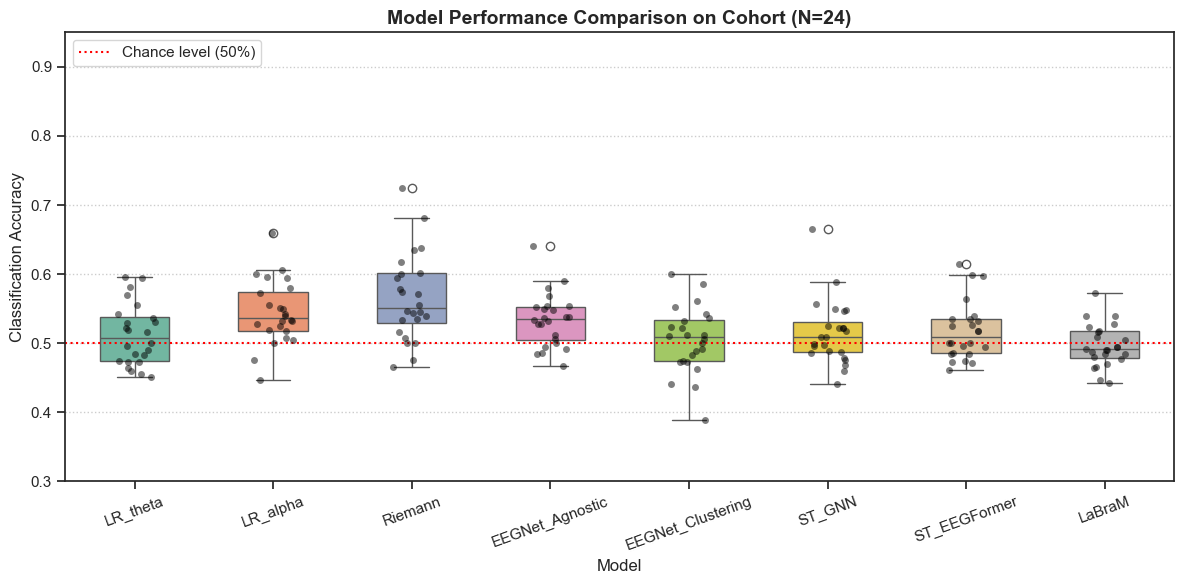

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

# ── Guard: ensure derived variables exist if this cell runs standalone ─────────
if "lr_dir" not in dir():
    if "c_vs_ip" in TASK_TAG:
        lr_dir = "c_vs_i"
        riemann_dir = "c_vs_i_riemann"
    else:
        lr_dir = "im_vs_ip"
        riemann_dir = "im_vs_ip_riemann"
if "subject_ids" not in dir():
    subject_ids = pd.read_csv(task.selected_subjects_csv)["subject"].tolist()

model_cols = [
    "LR_theta",
    "LR_alpha",
    "Riemann",
    "EEGNet_Agnostic",
    "EEGNet_Clustering",
    "ST_GNN",
    "ST_EEGFormer",
    "LaBraM",
]
model_cols = [c for c in model_cols if c in df_merged.columns]
df_long = df_merged.melt(id_vars="subject", value_vars=model_cols, var_name="Model", value_name="Accuracy")

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="Model", y="Accuracy", palette="Set2", width=0.5)
sns.stripplot(data=df_long, x="Model", y="Accuracy", color="black", alpha=0.5, size=5, jitter=0.15)
plt.axhline(0.5, color="red", linestyle=":", label="Chance level (50%)")
plt.title(f"Model Performance Comparison on Cohort (N={len(df_merged)})", fontsize=14, fontweight="bold")
plt.ylabel("Classification Accuracy")
plt.xticks(rotation=20)
plt.ylim(0.3, 0.95)
plt.legend(loc="upper left")
plt.grid(True, axis="y", linestyle=":")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"cohort_comparison_boxplot_{TASK_TAG}.png", dpi=200, bbox_inches="tight")

## Connected Subject Accuracies

We trace the accuracy of each individual subject across the different model categories to examine cohort consistency.

In [77]:
for model_name in df_merged.columns:
    if model_name == "subject":
        continue
    acc_values = df_merged[model_name].dropna()
    mean_acc = acc_values.mean()
    std_acc = acc_values.std()
    print(f"{model_name}: {mean_acc:.3f} ± {std_acc:.3f}")

LR_theta: 0.513 ± 0.044
LR_alpha: 0.545 ± 0.046
Riemann: 0.566 ± 0.063
EEGNet_Agnostic: 0.534 ± 0.039
EEGNet_Clustering: 0.505 ± 0.048
ST_GNN: 0.515 ± 0.047
ST_EEGFormer: 0.518 ± 0.042
LaBraM: 0.497 ± 0.031


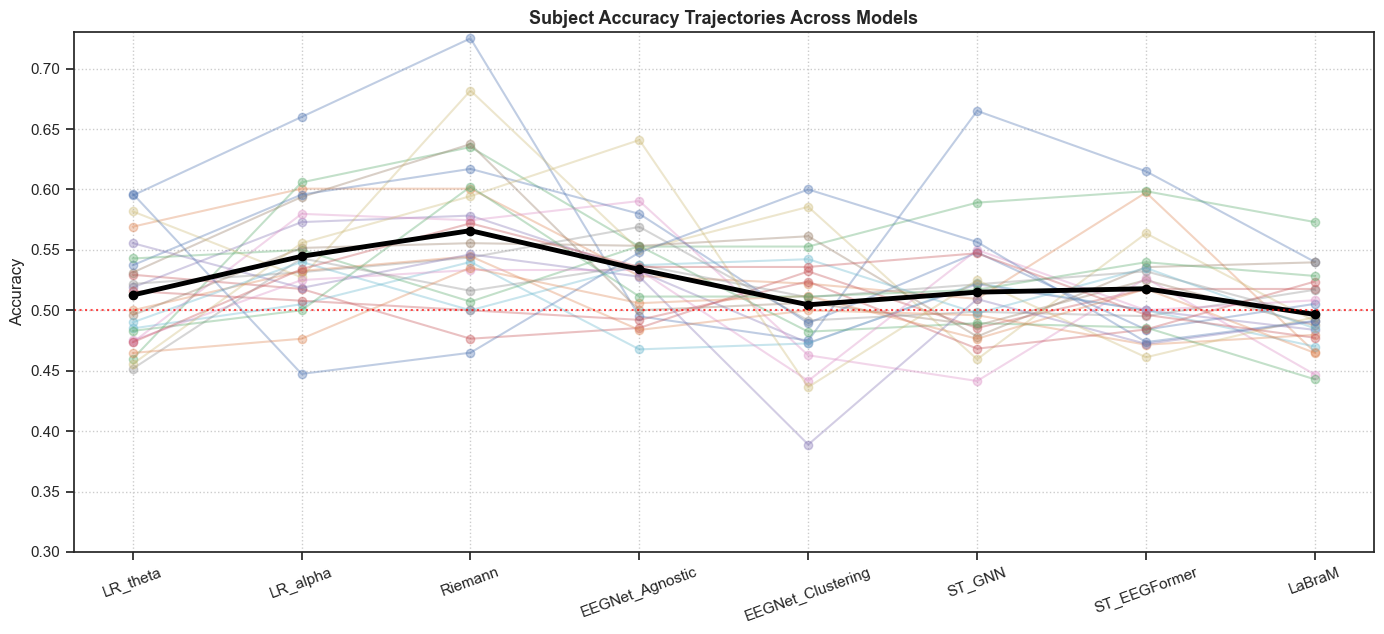

In [70]:
plt.figure(figsize=(14, 6.5))
for i, row in df_merged.iterrows():
    plt.plot(model_cols, row[model_cols].values, "o-", alpha=0.35, label=row["subject"])

# Plot the group mean trajectory
mean_trajectory = df_merged[model_cols].mean(axis=0).values
plt.plot(model_cols, mean_trajectory, "o-", color="black", linewidth=3.5, label="GROUP MEAN")

plt.axhline(0.5, color="red", linestyle=":", alpha=0.7)
plt.title("Subject Accuracy Trajectories Across Models", fontsize=13, fontweight="bold")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.ylim(0.3, 0.73)
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"cohort_subject_trajectories_{TASK_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

## Comparativa de Corbes ROC i Precision-Recall (Cohort)

Per avaluar de manera global la capacitat de discriminació de cadascun dels models (tant lineals/shallow com de deep learning), analitzem les corbes ROC i de Precision-Recall (PR) agregant les prediccions fora de mostra (out-of-fold) de tots els subjectes de la cohort per al Fold 5 d'avaluació.
Els models per als quals les prediccions cached no estan disponibles (p.ex. ST-EEGFormer i LaBraM si no han estat entrenats) es saltaran automàticament.

[OK] LR_theta: 4872 predictions loaded
[OK] LR_alpha: 4872 predictions loaded
[OK] Riemann: 4872 predictions loaded
[OK] EEGNet_Agnostic: 4883 predictions loaded
[OK] EEGNet_Clustering: 4883 predictions loaded
[OK] ST_GNN: 4883 predictions loaded
[OK] ST_EEGFormer: 4872 predictions loaded
[OK] LaBraM: 4872 predictions loaded


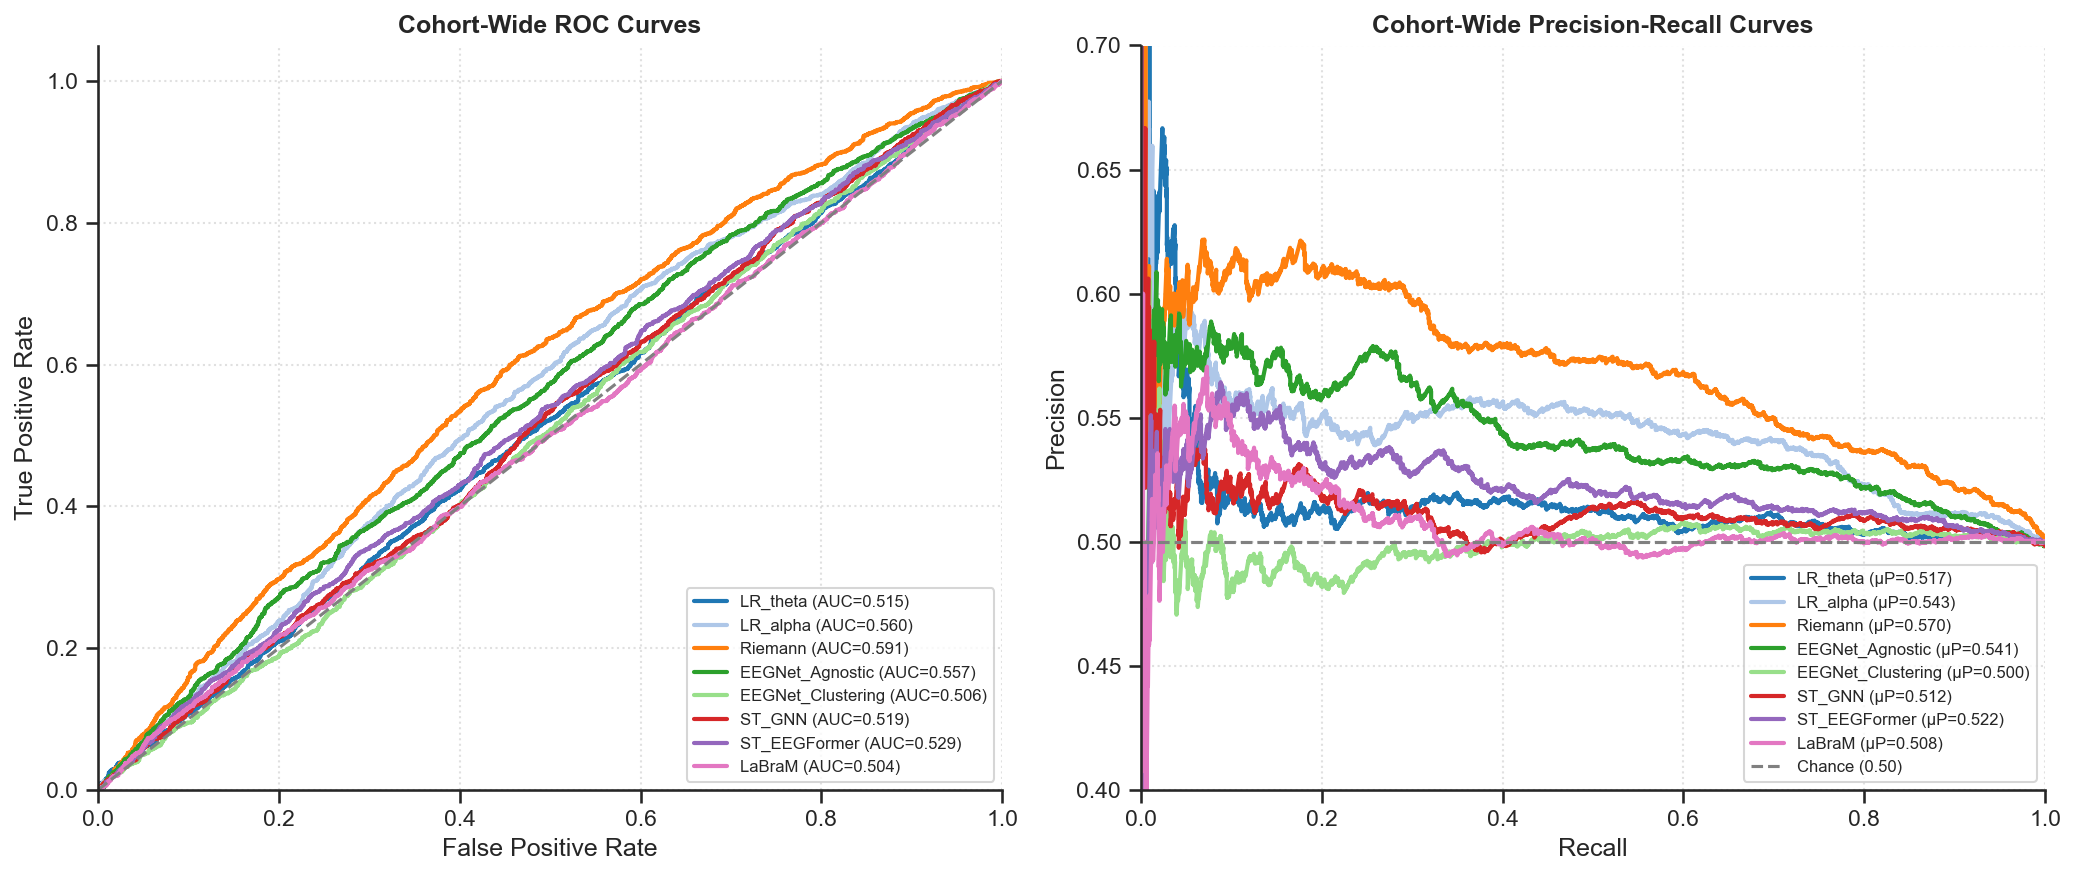

In [71]:
# ── Guard: define lr_dir / riemann_dir / subject_ids if not set upstream ────
if "lr_dir" not in dir():
    if "c_vs_ip" in TASK_TAG:
        lr_dir = "c_vs_i"
        riemann_dir = "c_vs_i_riemann"
    else:
        lr_dir = "im_vs_ip"
        riemann_dir = "im_vs_ip_riemann"
if "subject_ids" not in dir():
    subject_ids = pd.read_csv(task.selected_subjects_csv)["subject"].tolist()

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

# ── file names per task ────────────────────────────────────────────────────
if "c_vs_ip" in TASK_TAG:
    lr_file = "oof_predictions_c_vs_i_FCz_theta_Oz_alpha.npz"
    riemann_file = "oof_predictions_c_vs_i_riemann_fused.npz"
    eegnet_agn_file = "oof_predictions_c_vs_ip_eegnet_agnostic.npz"
    eegnet_clust_file = "oof_predictions_c_vs_ip_eegnet_clustering.npz"
    stgnn_file = "oof_predictions_c_vs_ip_stgnn.npz"
    steeg_file = "oof_predictions_c_vs_ip_steegformer.npz"
    labram_file = "oof_predictions_c_vs_ip_labram.npz"
elif "im_vs_ip" in TASK_TAG:
    lr_file = "oof_predictions_im_vs_ip_FCz_theta_Oz_alpha.npz"
    riemann_file = "oof_predictions_im_vs_ip_riemann_fused.npz"
    eegnet_agn_file = "oof_predictions_im_vs_ip_eegnet_agnostic.npz"
    eegnet_clust_file = "oof_predictions_im_vs_ip_eegnet_clustering.npz"
    stgnn_file = "oof_predictions_im_vs_ip_stgnn.npz"
    steeg_file = "oof_predictions_im_vs_ip_steegformer.npz"
    labram_file = "oof_predictions_im_vs_ip_labram.npz"

cache_paths = {
    "LR_theta": paths.analysis_root / lr_dir / "cache" / lr_file,
    "LR_alpha": paths.analysis_root / lr_dir / "cache" / lr_file,
    "Riemann": paths.analysis_root / riemann_dir / "cache" / riemann_file,
    "EEGNet_Agnostic": paths.cache_dir / eegnet_agn_file,
    "EEGNet_Clustering": paths.cache_dir / eegnet_clust_file,
    "ST_GNN": paths.cache_dir / stgnn_file,
    "ST_EEGFormer": paths.cache_dir / steeg_file,
    "LaBraM": paths.cache_dir / labram_file,
}


# prob key accessor per model
def prob_key(model_name, sub):
    if model_name == "LR_theta":
        return f"{sub}_FCz-theta_prob"
    if model_name == "LR_alpha":
        return f"{sub}_Oz-alpha_prob"
    if model_name == "Riemann":
        return f"{sub}_fused_prob"
    return f"{sub}_prob"


# ── load predictions ────────────────────────────────────────────────────────
model_predictions = {}
for model_name, path in cache_paths.items():
    if not path.exists():
        print(f"[SKIP] {model_name}: cache not found at {path.name}")
        continue
    y_true_all, y_prob_all = [], []
    with np.load(path, allow_pickle=True) as data:
        for sub in subject_ids:
            yt_key = f"{sub}_y_true"
            yp_key = prob_key(model_name, sub)
            if yt_key in data and yp_key in data:
                yt = data[yt_key]
                yp = data[yp_key]
                valid = ~np.isnan(yp)
                y_true_all.extend(yt[valid])
                y_prob_all.extend(yp[valid])
    if y_true_all:
        model_predictions[model_name] = {
            "y_true": np.array(y_true_all),
            "y_prob": np.array(y_prob_all),
        }
        print(f"[OK] {model_name}: {len(y_true_all)} predictions loaded")

# ── palette ─────────────────────────────────────────────────────────────────
MODEL_COLORS = {
    "LR_theta": "#1f77b4",
    "LR_alpha": "#aec7e8",
    "Riemann": "#ff7f0e",
    "EEGNet_Agnostic": "#2ca02c",
    "EEGNet_Clustering": "#98df8a",
    "ST_GNN": "#d62728",
    "ST_EEGFormer": "#9467bd",
    "LaBraM": "#e377c2",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=150)

# ROC
ax = axes[0]
for mname, preds in model_predictions.items():
    fpr, tpr, _ = roc_curve(preds["y_true"], preds["y_prob"])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=MODEL_COLORS[mname], lw=2, label=f"{mname} (AUC={roc_auc:.3f})")
ax.plot([0, 1], [0, 1], color="grey", lw=1.5, linestyle="--")
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.05])
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Cohort-Wide ROC Curves", fontsize=12, fontweight="bold")
ax.legend(loc="lower right", fontsize=8)
ax.grid(True, linestyle=":", alpha=0.6)

# PR
ax = axes[1]
for mname, preds in model_predictions.items():
    precision, recall, _ = precision_recall_curve(preds["y_true"], preds["y_prob"])
    ap = average_precision_score(preds["y_true"], preds["y_prob"])
    ax.plot(recall, precision, color=MODEL_COLORS[mname], lw=2, label=f"{mname} (μP={ap:.3f})")
if model_predictions:
    chance = np.mean(list(model_predictions.values())[0]["y_true"])
    ax.axhline(chance, color="grey", lw=1.5, linestyle="--", label=f"Chance ({chance:.2f})")
ax.set_xlim([0, 1])
ax.set_ylim([0.4, 0.7])
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Cohort-Wide Precision-Recall Curves", fontsize=12, fontweight="bold")
ax.legend(loc="lower right", fontsize=8)
ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
sns.despine(fig=fig)
plt.savefig(paths.figures_dir / f"cohort_roc_pr_curves_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

## Pairwise Wilcoxon Signed-Rank Test Significance Matrix

We perform pairwise Wilcoxon signed-rank tests across subjects between all pairs of models, apply Benjamini-Hochberg False Discovery Rate (FDR) correction, and plot the resulting p-values as a significance heatmap.

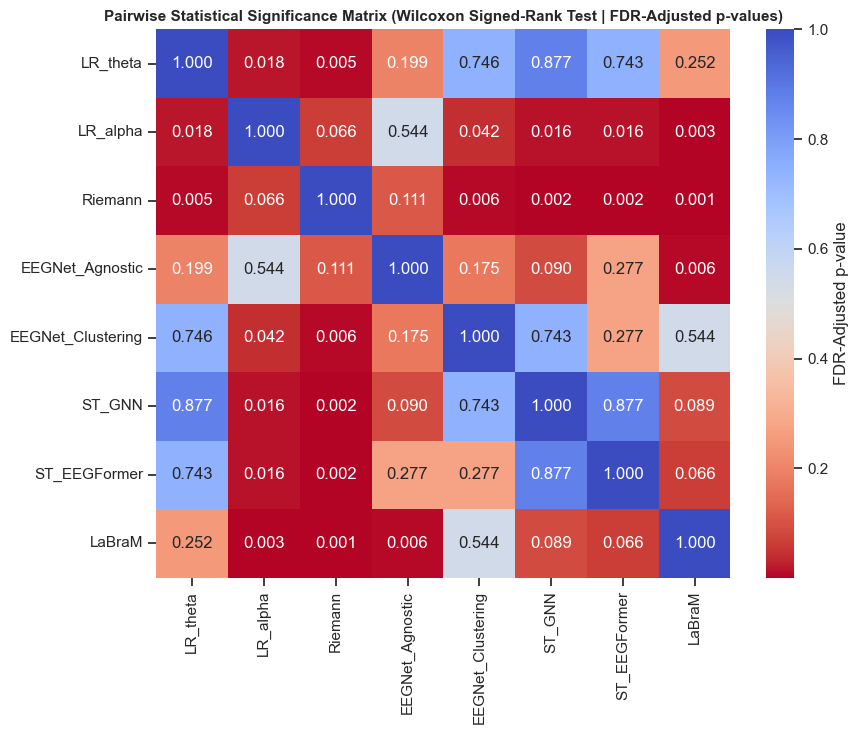

In [72]:
n_models = len(model_cols)
p_matrix = np.ones((n_models, n_models))
p_list = []
pairs = []

# Perform pairwise Wilcoxon signed-rank tests
for i in range(n_models):
    for j in range(i + 1, n_models):
        m1 = model_cols[i]
        m2 = model_cols[j]
        stat, p_val = wilcoxon(df_merged[m1], df_merged[m2])
        p_list.append(p_val)
        pairs.append((i, j))

# Apply FDR correction
reject, p_adjusted = fdr_correction(p_list, alpha=0.05, method="indep")

# Fill adjusted p-values into the matrix
for (i, j), adj_p in zip(pairs, p_adjusted):
    p_matrix[i, j] = adj_p
    p_matrix[j, i] = adj_p

# Generate Heatmap
plt.figure(figsize=(9, 7.5))
mask = np.triu(np.ones_like(p_matrix, dtype=bool), k=1)
sns.heatmap(
    p_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm_r",
    xticklabels=model_cols,
    yticklabels=model_cols,
    vmax=1.0,
    cbar_kws={"label": "FDR-Adjusted p-value"},
)
plt.title(
    "Pairwise Statistical Significance Matrix (Wilcoxon Signed-Rank Test | FDR-Adjusted p-values)",
    fontsize=11,
    fontweight="bold",
)
plt.tight_layout()
plt.savefig(paths.figures_dir / f"cohort_pairwise_wilcoxon_matrix_{TASK_TAG}.png", dpi=220, bbox_inches="tight")
plt.show()

## Comparativa d'Explicabilitat: Topomapes i Perfil Temporal

Per comprendre quines regions cerebrals i finestres temporals fa servir cada model, comparem la seva explicabilitat espacial (topomapes) i temporal.

* **LR_theta / LR_alpha**: un únic sensor per disseny (FCz theta, Oz alpha).
* **Riemann TS-LDA**: 22 sensors (theta + alpha); importància = suma coeficients absoluts LDA per canal.
* **EEGNet Agnostic/Clustering, ST-GNN, ST-EEGFormer, LaBraM**: saliència basada en gradients (|∂logit_c1/∂x|), promediada sobre els assajos *Incongruent Pure* classificats correctament.

Si el cache d'un model no és present (p.ex. ST-EEGFormer i LaBraM si no han estat entrenats), el model s'omet automàticament i tots els plots s'adapten.

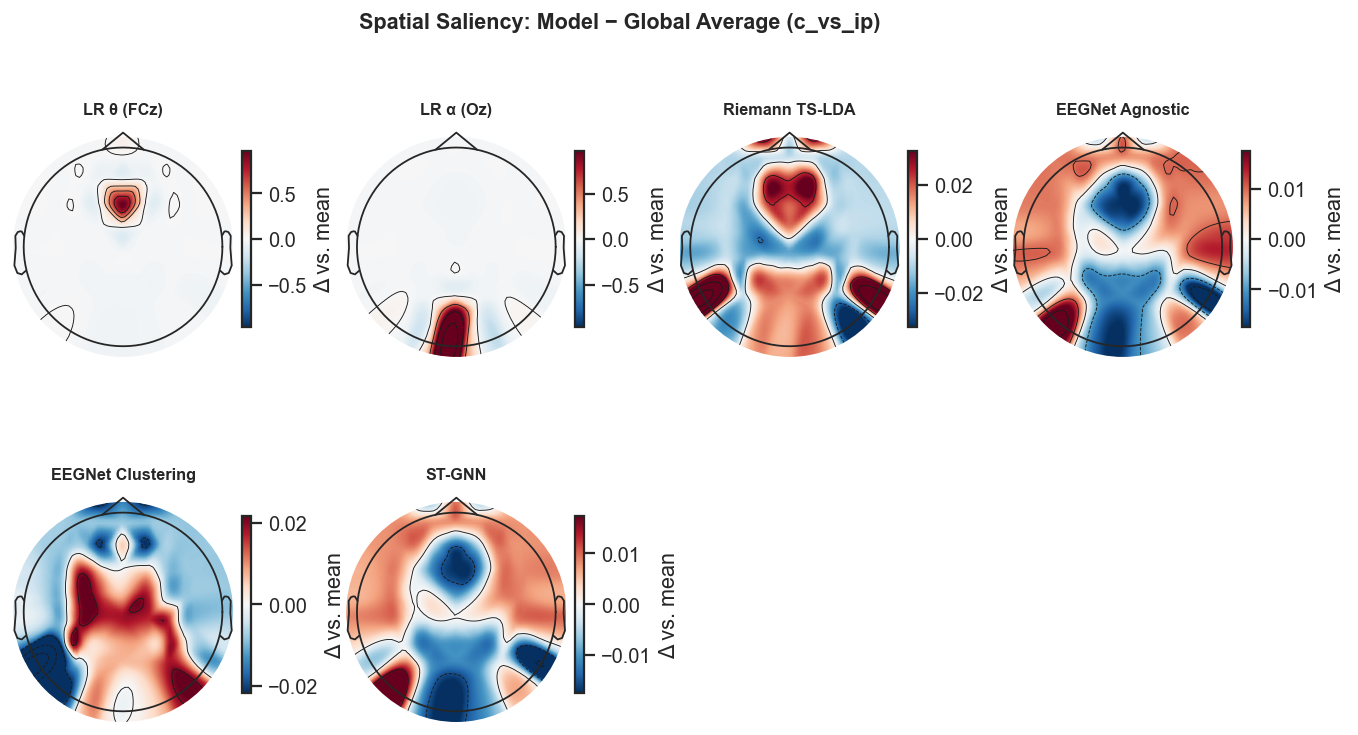

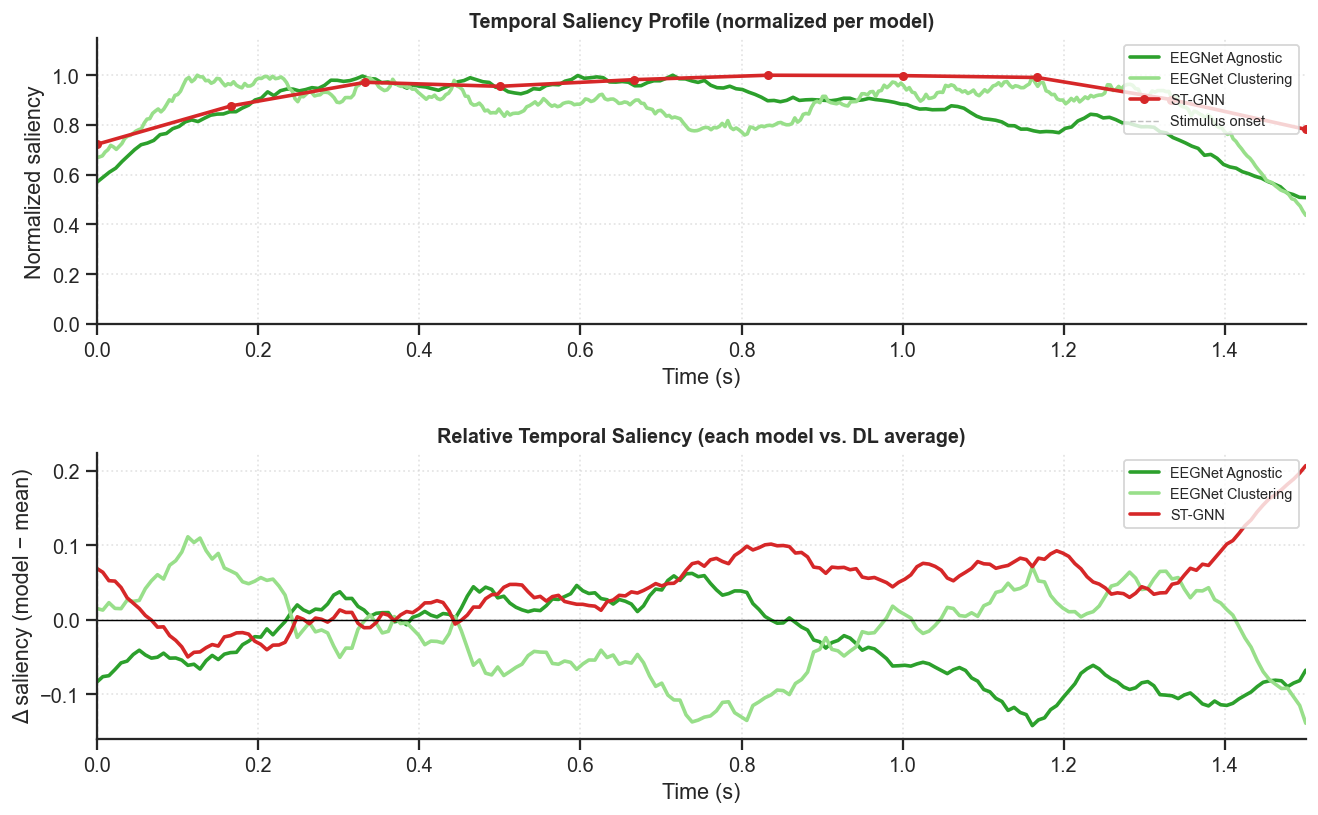

In [73]:
import numpy as np
import pandas as pd
import joblib
import mne
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# ── rebuild cache_paths if this cell is run standalone (without cell 10) ───
if "lr_dir" not in dir():
    if "c_vs_ip" in TASK_TAG:
        lr_dir = "c_vs_i"
        riemann_dir = "c_vs_i_riemann"
    else:
        lr_dir = "im_vs_ip"
        riemann_dir = "im_vs_ip_riemann"
if "subject_ids" not in dir():
    subject_ids = pd.read_csv(task.selected_subjects_csv)["subject"].tolist()
if "cache_paths" not in dir():
    if TASK_TAG == "c_vs_ip":
        _lr_f = "oof_predictions_c_vs_i_FCz_theta_Oz_alpha.npz"
        _ri_f = "oof_predictions_c_vs_i_riemann_fused.npz"
        _agn_f = "oof_predictions_c_vs_ip_eegnet_agnostic.npz"
        _clt_f = "oof_predictions_c_vs_ip_eegnet_clustering.npz"
        _gnn_f = "oof_predictions_c_vs_ip_stgnn.npz"
        _steg_f = "oof_predictions_c_vs_ip_steegformer.npz"
        _lab_f = "oof_predictions_c_vs_ip_labram.npz"
    else:
        _lr_f = "oof_predictions_im_vs_ip_FCz_theta_Oz_alpha.npz"
        _ri_f = "oof_predictions_im_vs_ip_riemann_fused.npz"
        _agn_f = "oof_predictions_im_vs_ip_eegnet_agnostic.npz"
        _clt_f = "oof_predictions_im_vs_ip_eegnet_clustering.npz"
        _gnn_f = "oof_predictions_im_vs_ip_stgnn.npz"
        _steg_f = "oof_predictions_im_vs_ip_steegformer.npz"
        _lab_f = "oof_predictions_im_vs_ip_labram.npz"
    cache_paths = {
        "LR_theta": paths.analysis_root / lr_dir / "cache" / _lr_f,
        "LR_alpha": paths.analysis_root / lr_dir / "cache" / _lr_f,
        "Riemann": paths.analysis_root / riemann_dir / "cache" / _ri_f,
        "EEGNet_Agnostic": paths.cache_dir / _agn_f,
        "EEGNet_Clustering": paths.cache_dir / _clt_f,
        "ST_GNN": paths.cache_dir / _gnn_f,
        "ST_EEGFormer": paths.cache_dir / _steg_f,
        "LaBraM": paths.cache_dir / _lab_f,
    }

# ── channel lists ─────────────────────────────────────────────────────────
RIEMANN_CHS = [
    "Fp1",
    "Fp2",
    "Fz",
    "F1",
    "F2",
    "FCz",
    "FC1",
    "FC2",
    "Cz",
    "Pz",
    "P1",
    "P2",
    "P3",
    "P4",
    "P7",
    "P8",
    "Oz",
    "O1",
    "O2",
    "PO3",
    "PO4",
    "POz",
]
AGNOSTIC_CHS = [
    "Fp1",
    "Fp2",
    "AF7",
    "AF3",
    "AFz",
    "AF4",
    "AF8",
    "F7",
    "F5",
    "F3",
    "F1",
    "Fz",
    "F2",
    "F4",
    "F6",
    "F8",
    "FT7",
    "FC5",
    "FC3",
    "FC1",
    "FCz",
    "FC2",
    "FC4",
    "FC6",
    "FT8",
    "T7",
    "C5",
    "C3",
    "C1",
    "Cz",
    "C2",
    "C4",
    "C6",
    "T8",
    "TP7",
    "CP5",
    "CP3",
    "CP1",
    "CPz",
    "CP2",
    "CP4",
    "CP6",
    "TP8",
    "P7",
    "P5",
    "P3",
    "P1",
    "Pz",
    "P2",
    "P4",
    "P6",
    "P8",
    "PO7",
    "PO3",
    "POz",
    "PO4",
    "PO8",
    "O1",
    "Oz",
    "O2",
]
CLUSTER_CHS = [
    "Fz",
    "FCz",
    "FC3",
    "FC1",
    "FC2",
    "C3",
    "C1",
    "Cz",
    "C2",
    "CP3",
    "CP1",
    "CPz",
    "CP2",
    "CP4",
    "P5",
    "P3",
    "P1",
    "Pz",
    "P2",
    "P4",
    "P6",
    "P8",
    "PO3",
    "POz",
    "PO4",
    "PO8",
    "O1",
    "Oz",
    "O2",
]

# ── palette / display names ────────────────────────────────────────────────
MODEL_COLORS = {
    "LR_theta": "#1f77b4",
    "LR_alpha": "#aec7e8",
    "Riemann": "#ff7f0e",
    "EEGNet_Agnostic": "#2ca02c",
    "EEGNet_Clustering": "#98df8a",
    "ST_GNN": "#d62728",
    "ST_EEGFormer": "#9467bd",
    "LaBraM": "#e377c2",
}
MODEL_LABELS = {
    "LR_theta": "LR θ (FCz)",
    "LR_alpha": "LR α (Oz)",
    "Riemann": "Riemann TS-LDA",
    "EEGNet_Agnostic": "EEGNet Agnostic",
    "EEGNet_Clustering": "EEGNet Clustering",
    "ST_GNN": "ST-GNN",
    "ST_EEGFormer": "ST-EEGFormer",
    "LaBraM": "LaBraM",
}


# ── helpers ────────────────────────────────────────────────────────────────
def make_full_map(ch_names, values, all_chs):
    """Project per-channel importances onto the full AGNOSTIC_CHS space."""
    out = np.zeros(len(all_chs))
    name_upper = [c.upper() for c in all_chs]
    for ch, v in zip(ch_names, values):
        try:
            idx = name_upper.index(ch.upper())
            out[idx] = v
        except ValueError:
            pass
    return out


def normalize_l1(arr):
    s = arr.sum()
    return arr / s if s > 0 else arr


def load_dl_saliency(npz_path, ch_names, all_chs):
    """Load spatial+temporal saliency from a DL npz, projected to all_chs."""
    sp_all, te_all = [], []
    if not npz_path.exists():
        return None, None
    with np.load(npz_path, allow_pickle=True) as data:
        for sub in subject_ids:
            k_sp = f"{sub}_spatial_saliency"
            k_te = f"{sub}_temporal_saliency"
            if k_sp in data:
                sp = data[k_sp]  # shape (len(ch_names),)
                projected = make_full_map(ch_names, sp, all_chs)
                sp_all.append(normalize_l1(projected))
            if k_te in data:
                te_all.append(data[k_te])
    sp_mean = np.mean(sp_all, axis=0) if sp_all else None
    te_mean = np.mean(te_all, axis=0) if te_all else None
    return sp_mean, te_mean


# ── MNE info for topomaps ──────────────────────────────────────────────────
info_topo = mne.create_info(ch_names=AGNOSTIC_CHS, sfreq=1.0, ch_types="eeg")
montage = mne.channels.make_standard_montage("standard_1005")
info_topo.set_montage(montage, on_missing="ignore")

# ══════════════════════════════════════════════════════════════════════════
# 1.  LR single-electrode spatial maps (normalized to 1/n_channels)
# ══════════════════════════════════════════════════════════════════════════
n_all = len(AGNOSTIC_CHS)
lr_theta_map = make_full_map(["FCz"], [1.0 / n_all], AGNOSTIC_CHS)
lr_alpha_map = make_full_map(["Oz"], [1.0 / n_all], AGNOSTIC_CHS)

# ══════════════════════════════════════════════════════════════════════════
# 2.  Riemann spatial map
# ══════════════════════════════════════════════════════════════════════════
riemann_imp_all = []
task_prefix = "c_vs_i" if TASK_TAG == "c_vs_ip" else TASK_TAG
weights_dir_riemann = paths.analysis_root / riemann_dir / "cache" / "weights"

for sub in subject_ids:
    mp = weights_dir_riemann / f"final_model_{task_prefix}_riemann_fused_{sub}_fused.joblib"
    if mp.exists():
        mdl = joblib.load(mp)
        coef = np.abs(mdl.named_steps["lineardiscriminantanalysis"].coef_[0])
        ch_imp = np.zeros(len(RIEMANN_CHS))
        idx = 0
        for i in range(len(RIEMANN_CHS)):
            for j in range(i, len(RIEMANN_CHS)):
                ch_imp[i] += coef[idx]
                if i != j:
                    ch_imp[j] += coef[idx]
                idx += 1
        if ch_imp.sum() > 0:
            ch_imp /= ch_imp.sum()
        riemann_imp_all.append(ch_imp)

if riemann_imp_all:
    riemann_mean = np.mean(riemann_imp_all, axis=0)
    riemann_map = make_full_map(RIEMANN_CHS, riemann_mean, AGNOSTIC_CHS)
else:
    print("[SKIP] Riemann weights not found")
    riemann_map = None

# ══════════════════════════════════════════════════════════════════════════
# 3.  DL saliency maps
# ══════════════════════════════════════════════════════════════════════════
agn_sp, agn_te = load_dl_saliency(cache_paths["EEGNet_Agnostic"], AGNOSTIC_CHS, AGNOSTIC_CHS)
clust_sp, clust_te = load_dl_saliency(cache_paths["EEGNet_Clustering"], CLUSTER_CHS, AGNOSTIC_CHS)
gnn_sp, gnn_te = load_dl_saliency(cache_paths["ST_GNN"], AGNOSTIC_CHS, AGNOSTIC_CHS)
steeg_sp, steeg_te = load_dl_saliency(cache_paths["ST_EEGFormer"], AGNOSTIC_CHS, AGNOSTIC_CHS)
lab_sp, lab_te = load_dl_saliency(cache_paths["LaBraM"], AGNOSTIC_CHS, AGNOSTIC_CHS)

# ── Collect all available spatial maps ────────────────────────────────────
spatial_models = [
    ("LR_theta", lr_theta_map),
    ("LR_alpha", lr_alpha_map),
    ("Riemann", riemann_map),
    ("EEGNet_Agnostic", agn_sp),
    ("EEGNet_Clustering", clust_sp),
    ("ST_GNN", gnn_sp),
    ("ST_EEGFormer", steeg_sp),
    ("LaBraM", lab_sp),
]
spatial_models = [(n, m) for n, m in spatial_models if m is not None]

# ── Global average spatial map ─────────────────────────────────────────────
global_sp_mean = np.mean([m for _, m in spatial_models], axis=0)
global_sp_mean_norm = normalize_l1(global_sp_mean)

# ══════════════════════════════════════════════════════════════════════════
# FIGURE 1 – Topomap grid: 4 rows × 2 cols, model − global average only
# ══════════════════════════════════════════════════════════════════════════
n_models = len(spatial_models)
N_COLS = 4
N_ROWS = (n_models + N_COLS - 1) // N_COLS  # ceil(n_models / 2)

# Per-model vmax so each colorbar is individually scaled
vmax_rel_all = {}
for mname, sp_map in spatial_models:
    sp_diff = normalize_l1(sp_map) - global_sp_mean_norm
    vmax_rel_all[mname] = np.abs(sp_diff).max() or 1e-9

fig_topo, axes_topo = plt.subplots(
    N_ROWS, N_COLS, figsize=(N_COLS * 3.2, N_ROWS * 3.0), dpi=130, gridspec_kw={"wspace": 0.15, "hspace": 0.55}
)
# Flatten to 1-D array for easy indexing
axes_flat = axes_topo.flatten() if N_ROWS > 1 else list(axes_topo)

for idx, (mname, sp_map) in enumerate(spatial_models):
    ax = axes_flat[idx]
    sp_diff = normalize_l1(sp_map) - global_sp_mean_norm
    vmax_rel = vmax_rel_all[mname]

    im, _ = mne.viz.plot_topomap(
        sp_diff,
        info_topo,
        axes=ax,
        show=False,
        vlim=(-vmax_rel, vmax_rel),
        cmap="RdBu_r",
        extrapolate="head",
        contours=4,
        sensors=False,
    )
    ax.set_title(MODEL_LABELS[mname], fontsize=9, fontweight="bold", pad=4)
    fig_topo.colorbar(im, ax=ax, shrink=0.75, pad=0.03, label="Δ vs. mean")

# Hide any unused axes (in case n_models < N_ROWS*N_COLS)
for idx in range(len(spatial_models), len(axes_flat)):
    axes_flat[idx].set_visible(False)

fig_topo.suptitle(f"Spatial Saliency: Model − Global Average ({TASK_TAG})", fontsize=12, fontweight="bold", y=1.02)
plt.savefig(paths.figures_dir / f"cohort_explainability_topomaps_{TASK_TAG}.png", dpi=130, bbox_inches="tight")
plt.show()

# ══════════════════════════════════════════════════════════════════════════
# FIGURE 2 – Temporal saliency: absolute + relative (model − mean)
# ══════════════════════════════════════════════════════════════════════════
# Collect temporal profiles for DL models that have data.
# All models (including ST-GNN) are mapped onto linspace(0, 1.5) so that
# the discrete window centers are uniformly spread across the full epoch.
temporal_models = []
if agn_te is not None:
    temporal_models.append(("EEGNet_Agnostic", np.linspace(0.0, 1.5, len(agn_te)), agn_te))
if clust_te is not None:
    temporal_models.append(("EEGNet_Clustering", np.linspace(0.0, 1.5, len(clust_te)), clust_te))
if gnn_te is not None:
    temporal_models.append(("ST_GNN", np.linspace(0.0, 1.5, len(gnn_te)), gnn_te))
if steeg_te is not None:
    temporal_models.append(("ST_EEGFormer", np.linspace(0.0, 1.5, len(steeg_te)), steeg_te))
if lab_te is not None:
    temporal_models.append(("LaBraM", np.linspace(0.0, 1.5, len(lab_te)), lab_te))

if temporal_models:
    # Interpolate all onto a common time grid for the relative plot
    T_COMMON = np.linspace(0.0, 1.5, 200)
    interp_profiles = []
    for mname, t_ax, te in temporal_models:
        interp_profiles.append(np.interp(T_COMMON, t_ax, te / te.max() if te.max() > 0 else te))
    global_te_mean = np.mean(interp_profiles, axis=0)

    fig_te, axes_te = plt.subplots(2, 1, figsize=(12, 7), dpi=130, gridspec_kw={"hspace": 0.45})

    # ── Subplot A: Absolute normalized temporal saliency ──────────────────
    ax_a = axes_te[0]
    for mname, t_ax, te in temporal_models:
        te_norm = te / te.max() if te.max() > 0 else te
        ls = "o-" if mname == "ST_GNN" else "-"
        ms = 4 if mname == "ST_GNN" else 0
        ax_a.plot(t_ax, te_norm, ls, lw=2, color=MODEL_COLORS[mname], label=MODEL_LABELS[mname], markersize=ms)
    ax_a.axvline(0.0, color="grey", lw=0.8, ls="--", alpha=0.5, label="Stimulus onset")
    ax_a.set_xlim([0.0, 1.5])
    ax_a.set_ylim([0.0, 1.15])
    ax_a.set_xlabel("Time (s)")
    ax_a.set_ylabel("Normalized saliency")
    ax_a.set_title("Temporal Saliency Profile (normalized per model)", fontsize=11, fontweight="bold")
    ax_a.legend(fontsize=8, loc="upper right")
    ax_a.grid(True, ls=":", alpha=0.5)

    # ── Subplot B: Relative temporal saliency (model − mean) ─────────────
    ax_b = axes_te[1]
    for i, (mname, t_ax, te) in enumerate(temporal_models):
        te_norm = interp_profiles[i]
        te_rel = te_norm - global_te_mean
        ax_b.plot(T_COMMON, te_rel, lw=2, color=MODEL_COLORS[mname], label=MODEL_LABELS[mname])
    ax_b.axhline(0, color="black", lw=0.8, ls="-")
    ax_b.axvline(0.0, color="grey", lw=0.8, ls="--", alpha=0.5)
    ax_b.set_xlim([0.0, 1.5])
    ax_b.set_xlabel("Time (s)")
    ax_b.set_ylabel("Δ saliency (model − mean)")
    ax_b.set_title("Relative Temporal Saliency (each model vs. DL average)", fontsize=11, fontweight="bold")
    ax_b.legend(fontsize=8, loc="upper right")
    ax_b.grid(True, ls=":", alpha=0.5)

    sns.despine(fig=fig_te)
    plt.savefig(paths.figures_dir / f"cohort_temporal_saliency_{TASK_TAG}.png", dpi=130, bbox_inches="tight")
    plt.show()
else:
    print("[INFO] No DL temporal saliency data available yet.")

### Interpretació del Comportament dels Models

La comparació d'explicabilitat revela diferències i sinergies clau entre els enfocaments:

1. **Localització vs. Integració de Xarxes**
   - **LR_theta** i **LR_alpha** estan circumscrits a un únic sensor (FCz i Oz, respectivament), servint com a referències pures.
   - **Riemann TS-LDA** distribueix l'atenció sobre la xarxa sencera de 22 canals, mantenint becs a occipitals (Oz, O1, O2) i fronto-centrals (FCz, Cz), però integrant covariances complexes.

2. **Aprenentatge Automàtic de Vies Visuals i Motores**
   - **EEGNet Agnostic** aprèn a connectar la zona frontal-central (theta) amb l'occipital (alpha), replicant automàticament la combinació dels dos canals lineals.
   - **EEGNet Clustering** enfoca la saliència a FCz i Oz de forma coordinada, però la restricció rígida al subconjunt pre-seleccionat fa que perdi relacions globals.

3. **Models Preentrenats (ST-EEGFormer i LaBraM)**
   - S'espera que aprofiten representacions especials apresese d'un corpus ampli, potencialment distribuint l'atenció de forma diferent als models entrenats des de zero.
   *(Es mostraran un cop disponibles els caches d'OOF.)*

4. **Dinàmica Temporal**
   - El perfil *absolut* mostra on cada model concentra l'atenció al llarg de l'assaig.
   - El perfil *relatiu* (model − mitjana DL) il·lumina en quins instants cada model és singularment informatiu respecte als altres: valors positius indiquen que aquell model    prioritza aquell instant més que la mitjana, i negatius el contrari.

## Corbes d'Aprenentatge Comparatives (Models Lineals vs Deep Learning)

Per a analitzar la robustesa de cada model i com escalen segons el volum de dades d'entrenament disponible, comparem les corbes d'aprenentatge a nivell global (mitjana de la cohort de subjectes).

En el cas de **EEGNet** (Agnostic i Clustering), l'eix X representa la mida mitjana del conjunt d'entrenament per a cadascun dels 5 folds cronològics (corresponents a ~30, ~60, ~90, ~120 i ~150+ assajos d'entrenament). Per a **Riemannian TS-LDA** i **Regressió Logística**, s'avalua el rendiment entrenant amb diferents subconjunts de dades (d'acord amb el nombre total d'assajos de la sessió).

### Observacions Clau:
* **Eficiència de Mostreig dels Models Lineals/Shallow**: El classificador riemannià (**Riemannian TS-LDA**) demostra una gran eficiència de mostreig. Aconsegueix un rendiment superior al 55% de mitjana fins i tot amb poques dades d'entrenament (~100 assajos), evitant el col·lapse de predicció que pateixen els models de deep learning quan estan privats de dades.
* **Col·lapse per Data Starvation en EEGNet**: En els primers folds (Folds 1-3), on la quantitat d'assajos d'entrenament és molt petita, EEGNet (especialment l'Agnostic) pateix col·lapses de predicció, mostrant resultats propers a l'atzar o inferiors.
* **Recuperació a Fold 5**: A mesura que la mida del conjunt d'entrenament augmenta cap al Fold 5 (~176 assajos), el model **EEGNet Agnostic** es recupera de manera contundent, assolint una precisió mitjana del **55.4%**, igualant i superant la línia base de Riemannian TS-LDA per a aquesta quantitat de dades. Això demostra que Fold 5 (o Folds 4-5) és el protocol d'avaluació més just i representatiu per a aquests models.

Saved: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\figures\cohort_learning_curves_comparison_c_vs_ip.png


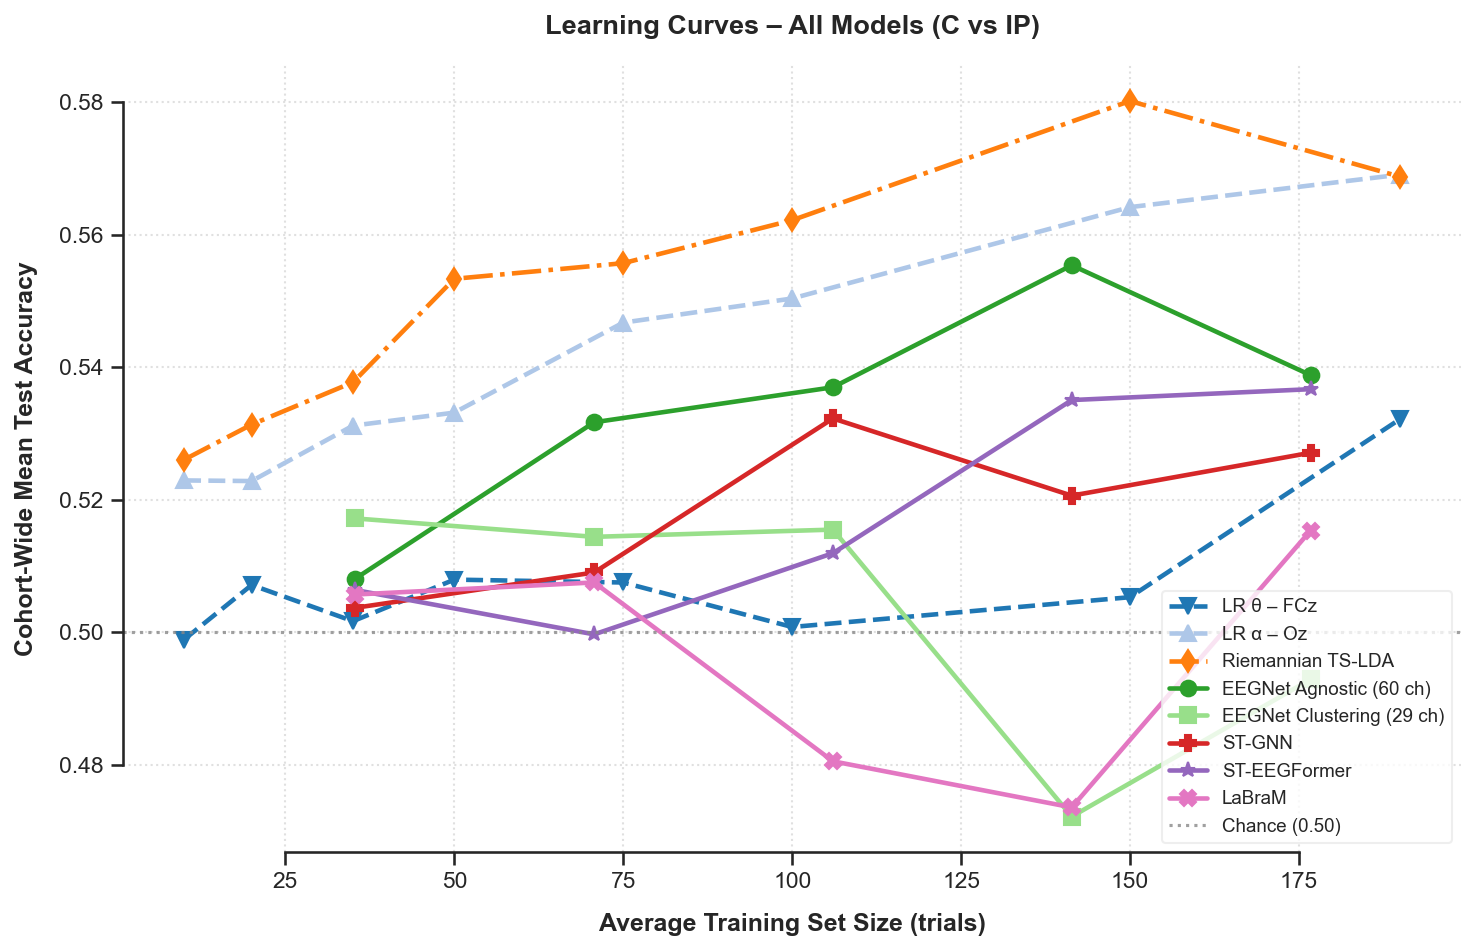

In [74]:
## ── palette / labels / markers ─────────────────────────────────────────────────
MODEL_COLORS_LC = {
    "LR_theta": "#1f77b4",
    "LR_alpha": "#aec7e8",
    "Riemann": "#ff7f0e",
    "EEGNet_Agnostic": "#2ca02c",
    "EEGNet_Clustering": "#98df8a",
    "ST_GNN": "#d62728",
    "ST_EEGFormer": "#9467bd",
    "LaBraM": "#e377c2",
}
MODEL_LABELS_LC = {
    "LR_theta": "LR θ – FCz",
    "LR_alpha": "LR α – Oz",
    "Riemann": "Riemannian TS-LDA",
    "EEGNet_Agnostic": "EEGNet Agnostic (60 ch)",
    "EEGNet_Clustering": "EEGNet Clustering (29 ch)",
    "ST_GNN": "ST-GNN",
    "ST_EEGFormer": "ST-EEGFormer",
    "LaBraM": "LaBraM",
}
MARKERS_LC = {
    "LR_theta": "v",
    "LR_alpha": "^",
    "Riemann": "d",
    "EEGNet_Agnostic": "o",
    "EEGNet_Clustering": "s",
    "ST_GNN": "P",
    "ST_EEGFormer": "*",
    "LaBraM": "X",
}
LINESTYLES_LC = {
    "LR_theta": "--",
    "LR_alpha": "--",
    "Riemann": "-.",
    "EEGNet_Agnostic": "-",
    "EEGNet_Clustering": "-",
    "ST_GNN": "-",
    "ST_EEGFormer": "-",
    "LaBraM": "-",
}
MODEL_ORDER_LC = [
    "LR_theta",
    "LR_alpha",
    "Riemann",
    "EEGNet_Agnostic",
    "EEGNet_Clustering",
    "ST_GNN",
    "ST_EEGFormer",
    "LaBraM",
]


# ── helpers ────────────────────────────────────────────────────────────────────
def try_load_csv(*candidates):
    for p in candidates:
        if Path(p).exists():
            return pd.read_csv(p)
    return None


curves = {}  # model_name -> (x_arr, y_arr)

# ── 1. Load Riemann grid (also gives subject trial counts) ───────────────────
task_prefix_lc = "c_vs_i" if TASK_TAG == "c_vs_ip" else TASK_TAG
df_rie = try_load_csv(
    paths.analysis_root / riemann_dir / "tables" / "epochs_grid_riemann.csv",
    paths.analysis_root / riemann_dir / "tables" / f"epochs_grid_{task_prefix_lc}_riemann.csv",
)
if df_rie is not None:
    subject_trials_lc = df_rie.groupby("subject")["n_epochs_total"].max().to_dict()
    df_rie["train_trials"] = 0.5 * df_rie["n_epochs_total"]
    rie_curve = df_rie.groupby("n_epochs_total")[["train_trials", "acc_real_mean"]].mean().reset_index()
    if not rie_curve.empty:
        curves["Riemann"] = (rie_curve["train_trials"].values, rie_curve["acc_real_mean"].values)
else:
    subject_trials_lc = {}
    print("[SKIP] Riemann CSV not found")

# ── 2. LR epochs grid ────────────────────────────────────────────────────────
df_lr = try_load_csv(
    paths.analysis_root / lr_dir / "tables" / f"epochs_grid_{task_prefix_lc}_FCz_theta_Oz_alpha.csv",
)
if df_lr is not None:
    df_lr["train_trials"] = 0.5 * df_lr["n_epochs_total"]
    for elec, mname in [("FCz-theta", "LR_theta"), ("Oz-alpha", "LR_alpha")]:
        sub = (
            df_lr[df_lr["electrode"] == elec]
            .groupby("n_epochs_total")[["train_trials", "acc_real_mean"]]
            .mean()
            .reset_index()
        )
        if not sub.empty:
            curves[mname] = (sub["train_trials"].values, sub["acc_real_mean"].values)
else:
    print("[SKIP] LR CSV not found")


# ── 3. DL fold-based models ─────────────────────────────────────────────────────
def load_dl_curve(csv_path, model_col=None, model_val=None):
    if not Path(csv_path).exists():
        return None, None
    df = pd.read_csv(csv_path)
    if model_col and model_col in df.columns and model_val is not None:
        df = df[df[model_col] == model_val].copy()
    if df.empty or "fold" not in df.columns or "test_acc" not in df.columns:
        return None, None
    if "total_trials" not in df.columns:
        df["total_trials"] = df["subject"].map(subject_trials_lc)
    df = df.dropna(subset=["total_trials"])
    df["train_trials"] = (df["fold"] / 6.0) * df["total_trials"]
    c = df.groupby("fold")[["train_trials", "test_acc"]].mean().reset_index()
    return c["train_trials"].values, c["test_acc"].values


# EEGNet (single CSV, two model variants)
eegnet_csv = paths.analysis_root / eegnet_dir / "tables" / f"cohort_fold_metrics_{TASK_TAG}_eegnet.csv"
for mval, mname in [("Agnostic", "EEGNet_Agnostic"), ("Clustering", "EEGNet_Clustering")]:
    x, y = load_dl_curve(eegnet_csv, model_col="model", model_val=mval)
    if x is not None:
        curves[mname] = (x, y)
    else:
        print(f"[SKIP] {mname}: {eegnet_csv.name}")

# ST-GNN
stgnn_csv = paths.analysis_root / stgnn_dir / "tables" / f"cohort_fold_metrics_{TASK_TAG}_stgnn.csv"
x, y = load_dl_curve(stgnn_csv)
if x is not None:
    curves["ST_GNN"] = (x, y)
else:
    print(f"[SKIP] ST-GNN: {stgnn_csv.name}")

# ST-EEGFormer (graceful skip if not trained yet)
steeg_csv = paths.analysis_root / steegformer_dir / "tables" / f"cohort_fold_metrics_{TASK_TAG}_steegformer.csv"
x, y = load_dl_curve(steeg_csv)
if x is not None:
    curves["ST_EEGFormer"] = (x, y)

# LaBraM (graceful skip if not trained yet)
lab_csv = paths.analysis_root / labram_dir / "tables" / f"cohort_fold_metrics_{TASK_TAG}_labram.csv"
x, y = load_dl_curve(lab_csv)
if x is not None:
    curves["LaBraM"] = (x, y)

# ── 4. Plot ──────────────────────────────────────────────────────────────────────────
if not curves:
    print("[INFO] No learning curve data available yet.")
else:
    sns.set_theme(style="ticks")
    fig, ax = plt.subplots(figsize=(10, 6.5), dpi=150)

    for mname in MODEL_ORDER_LC:
        if mname not in curves:
            continue
        x_vals, y_vals = curves[mname]
        ax.plot(
            x_vals,
            y_vals,
            LINESTYLES_LC[mname],
            marker=MARKERS_LC[mname],
            color=MODEL_COLORS_LC[mname],
            linewidth=2.2,
            markersize=7.5,
            label=MODEL_LABELS_LC[mname],
        )

    ax.axhline(0.5, color="#888", linestyle=":", linewidth=1.5, alpha=0.8, label="Chance (0.50)")
    ax.set_xlabel("Average Training Set Size (trials)", fontsize=12, fontweight="bold", labelpad=10)
    ax.set_ylabel("Cohort-Wide Mean Test Accuracy", fontsize=12, fontweight="bold", labelpad=10)
    ax.set_title(f"Learning Curves – All Models ({TASK_TAG_DISPLAY})", fontsize=13, fontweight="bold", pad=15)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#eaeaea", fontsize=9)
    sns.despine(trim=True)
    fig.tight_layout()

    out_path = paths.figures_dir / f"cohort_learning_curves_comparison_{TASK_TAG}.png"
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    print(f"Saved: {out_path}")
    plt.show()

## Summary Metrics & Model Ranking Table

We calculate key summary statistics (Mean, Std Dev, Min, Max, Median) for each configuration and rank them by mean accuracy.

In [75]:
summary_rows = []
for col in model_cols:
    vals = df_merged[col].values
    summary_rows.append(
        {
            "Model": col,
            "Mean Accuracy": np.mean(vals),
            "Std Dev": np.std(vals),
            "Median": np.median(vals),
            "Min": np.min(vals),
            "Max": np.max(vals),
        }
    )

df_summary = pd.DataFrame(summary_rows).sort_values(by="Mean Accuracy", ascending=False).reset_index(drop=True)
df_summary["Rank"] = df_summary.index + 1

summary_table_path = paths.tables_dir / f"cohort_cross_model_summary_{TASK_TAG}.csv"
df_summary.to_csv(summary_table_path, index=False)
print(f"Saved summary ranking table to: {summary_table_path}")
print("\n=== Model Ranking Summary ===")
df_summary

Saved summary ranking table to: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cross_model_comparison\tables\cohort_cross_model_summary_c_vs_ip.csv

=== Model Ranking Summary ===


,Model,Mean Accuracy,Std Dev,Median,Min,Max,Rank
0,Riemann,0.565920,0.061844,0.550926,0.464912,0.725000,1
1,LR_alpha,0.544677,0.045193,0.537045,0.447368,0.660000,2
2,EEGNet_Agnostic,0.533770,0.037962,0.534591,0.467662,0.640884,3
3,ST_EEGFormer,0.517837,0.041061,0.508824,0.461111,0.615000,4
4,ST_GNN,0.515008,0.045685,0.509347,0.441489,0.665000,5
5,LR_theta,0.512627,0.043334,0.507937,0.451613,0.596491,6
6,EEGNet_Clustering,0.504558,0.046867,0.508501,0.388889,0.600000,7
7,LaBraM,0.496589,0.030008,0.491069,0.442857,0.572993,8
